In [51]:
# Visualización de datos
import pandas as pd

ruta = "C:/Users/julia/Downloads/_8662591bff874fdab201297ba3e73410_genre_dataset.txt"

# Buscar la línea donde comienza el verdadero encabezado
with open(ruta, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if line.startswith("%genre"):
            header_line = i
            break

print("El encabezado real está en la línea:", header_line)

# Cargar desde esa línea
df = pd.read_csv(
    ruta,
    sep=",",
    skiprows=header_line,
    header=0
)

# Quitar el % del nombre de la primera columna
df.columns = df.columns.str.replace("%", "", regex=False)

print("\nDimensiones:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras filas:")
display(df.head())

El encabezado real está en la línea: 9

Dimensiones: (59600, 34)

Columnas:
['genre', 'track_id', 'artist_name', 'title', 'loudness', 'tempo', 'time_signature', 'key', 'mode', 'duration', 'avg_timbre1', 'avg_timbre2', 'avg_timbre3', 'avg_timbre4', 'avg_timbre5', 'avg_timbre6', 'avg_timbre7', 'avg_timbre8', 'avg_timbre9', 'avg_timbre10', 'avg_timbre11', 'avg_timbre12', 'var_timbre1', 'var_timbre2', 'var_timbre3', 'var_timbre4', 'var_timbre5', 'var_timbre6', 'var_timbre7', 'var_timbre8', 'var_timbre9', 'var_timbre10', 'var_timbre11', 'var_timbre12']

Primeras filas:


,genre,track_id,artist_name,title,loudness,tempo,time_signature,key,mode,duration,...,var_timbre3,var_timbre4,var_timbre5,var_timbre6,var_timbre7,var_timbre8,var_timbre9,var_timbre10,var_timbre11,var_timbre12
0,classic pop and rock,TRFCOOU128F427AEC0,Blue Oyster Cult,Mes Dames Sarat,-8.697,155.007,1,9,1,246.33424,...,1255.514569,580.030472,598.485223,575.337671,322.068603,321.726029,232.700609,186.805303,181.938688,151.508011
1,classic pop and rock,TRNJTPB128F427AE9F,Blue Oyster Cult,Screams,-10.659,148.462,1,4,0,189.80526,...,2007.653070,1043.474073,585.694981,564.013736,510.177022,400.200186,365.119588,238.099708,197.933757,251.577525
2,classic pop and rock,TRLFJHA128F427AEEA,Blue Oyster Cult,Dance The Night Away,-13.494,112.909,1,10,0,158.19710,...,1204.856777,2736.520024,730.233239,665.203452,535.775111,439.335059,486.822970,265.333860,447.097987,251.880724
3,classic pop and rock,TRCQZAG128F427DB97,Blue Oyster Cult,Debbie Denise,-12.786,117.429,4,7,1,250.22649,...,809.755802,563.908070,492.803819,378.382799,372.875044,231.941957,246.313305,168.400152,85.282462,339.897173
4,classic pop and rock,TRNXMNM128F427DB8C,Blue Oyster Cult,(Don't Fear) The Reaper,-14.093,141.536,4,9,0,307.06893,...,1093.684935,343.556047,889.163314,218.111796,304.862864,178.352161,440.478867,142.669283,81.061326,208.355152


In [52]:
# Visualizar cuantos generos hay
print(df["genre"].value_counts())
print("Número de géneros:", df["genre"].nunique())

print("\nGéneros:")
print(df["genre"].unique())
# Generos que competen en el proyecto 
#1 Dance and electronic.
#2 Jazz and blues.
#3 Soul and reggae.
#4 Punk.
#5 Metal.

genre
classic pop and rock     23895
folk                     13192
dance and electronica     4935
jazz and blues            4334
soul and reggae           4016
punk                      3200
metal                     2103
classical                 1874
pop                       1617
hip-hop                    434
Name: count, dtype: int64
Número de géneros: 10

Géneros:
['classic pop and rock' 'punk' 'folk' 'pop' 'dance and electronica'
 'metal' 'jazz and blues' 'classical' 'hip-hop' 'soul and reggae']


In [53]:
# Limpieza y preparación del dataset
generos = [
    "dance and electronica",
    "jazz and blues",
    "soul and reggae",
    "punk",
    "metal"
]

df_model = df[df["genre"].isin(generos)].copy()

print("Dataset original:", df.shape)
print("Dataset después de ignorar los otros géneros:", df_model.shape)

print("\nDistribución de las 5 clases:")
print(df_model["genre"].value_counts())
# Revisión de generos
print(df_model["genre"].unique())

Dataset original: (59600, 34)
Dataset después de ignorar los otros géneros: (18588, 34)

Distribución de las 5 clases:
genre
dance and electronica    4935
jazz and blues           4334
soul and reggae          4016
punk                     3200
metal                    2103
Name: count, dtype: int64
['punk' 'dance and electronica' 'metal' 'jazz and blues' 'soul and reggae']


In [54]:
# Eliminación de identificador, titulo y artista
df_model = df_model.drop(columns=[
    "track_id",
    "title",
    "artist_name"
])

print("Dimensiones después de eliminar las columnas:")
print(df_model.shape)

display(df_model.head())
# Revisión de valores faltantes

# Se verifica si existen valores ausentes en las variables utilizadas
# para la clasificación. Los valores faltantes pueden afectar el entrenamiento
# de los modelos y deben ser identificados antes de realizar la división
# de los datos.

print("Valores faltantes por columna:")
print(df_model.isnull().sum())

print("\nTotal de valores faltantes:")
print(df_model.isnull().sum().sum())
# Revisión de registros duplicados

# Se verifica si existen filas completamente duplicadas dentro del dataset.
# Los duplicados pueden provocar que observaciones muy similares aparezcan
# tanto en entrenamiento como en validación o prueba, afectando la evaluación
# del modelo.

print("Número de filas duplicadas:")
print(df_model.duplicated().sum())

Dimensiones después de eliminar las columnas:
(18588, 31)


,genre,loudness,tempo,time_signature,key,mode,duration,avg_timbre1,avg_timbre2,avg_timbre3,...,var_timbre3,var_timbre4,var_timbre5,var_timbre6,var_timbre7,var_timbre8,var_timbre9,var_timbre10,var_timbre11,var_timbre12
23895,punk,-11.692,215.680,4,7,1,390.21669,37.407679,-48.922061,-36.440067,...,2557.448481,1863.338318,1438.709380,1409.052050,469.471179,701.122890,205.498069,416.394306,308.376192,205.342829
23896,punk,-8.465,181.727,4,2,1,222.01424,47.481769,48.860331,24.236359,...,754.186431,594.959707,744.527096,576.282914,312.065861,341.816107,438.786829,217.185562,172.488676,107.900188
23897,punk,-9.802,143.258,1,7,1,234.97098,45.215285,35.170036,8.846779,...,2501.020031,723.805256,875.340084,479.630136,367.788692,315.335050,383.704213,198.750683,147.167370,132.249188
23898,punk,-10.002,198.678,4,9,1,171.12771,45.416330,23.102570,17.693610,...,1409.018434,995.247862,693.201666,643.482582,323.476615,284.213170,266.876326,173.105332,199.876823,142.242248
23899,punk,-9.782,197.259,4,7,1,168.80281,45.392111,27.333599,18.574181,...,2650.098441,940.580882,781.728128,582.849445,374.209090,263.218574,396.554976,211.750683,196.885589,177.964331


Valores faltantes por columna:
genre             0
loudness          0
tempo             0
time_signature    0
key               0
mode              0
duration          0
avg_timbre1       0
avg_timbre2       0
avg_timbre3       0
avg_timbre4       0
avg_timbre5       0
avg_timbre6       0
avg_timbre7       0
avg_timbre8       0
avg_timbre9       0
avg_timbre10      0
avg_timbre11      0
avg_timbre12      0
var_timbre1       0
var_timbre2       0
var_timbre3       0
var_timbre4       0
var_timbre5       0
var_timbre6       0
var_timbre7       0
var_timbre8       0
var_timbre9       0
var_timbre10      0
var_timbre11      0
var_timbre12      0
dtype: int64

Total de valores faltantes:
0
Número de filas duplicadas:
6


In [55]:
# Eliminación de registros duplicados

# Se identificaron 6 filas duplicadas y no se encontraron valores faltantes.
# Los registros duplicados se eliminan antes de realizar la división entre
# entrenamiento, validación y prueba para evitar que una misma observación
# pueda aparecer en diferentes subconjuntos y producir una evaluación
# artificialmente optimista del modelo.

duplicados = df_model.duplicated().sum()

print("Registros duplicados encontrados:", duplicados)

df_model = df_model.drop_duplicates().reset_index(drop=True)

print("Duplicados después de la eliminación:", df_model.duplicated().sum())
print("Nuevas dimensiones del dataset:", df_model.shape)

Registros duplicados encontrados: 6
Duplicados después de la eliminación: 0
Nuevas dimensiones del dataset: (18582, 31)


In [56]:
# Se dividió el conjunto de datos en tres subconjuntos: entrenamiento, validación y prueba,
# utilizando una proporción final de 64% para entrenamiento, 16% para validación y 20% para prueba.
# Primero, se reservó el 20% de los datos para el conjunto de prueba, el cual se mantuvo separado y 
# no se utilizará durante el entrenamiento ni durante la selección de los modelos. El 80% restante 
# se dividió posteriormente en 80% para entrenamiento y 20% para validación, obteniendo así la 
# proporción final de 64%, 16% y 20%.

# Esta división permite utilizar el conjunto de entrenamiento para ajustar los modelos, el conjunto 
# de validación para comparar modelos y seleccionar hiperparámetros, y finalmente el conjunto de 
# prueba para realizar una evaluación objetiva del modelo seleccionado sobre datos que no fueron 
# utilizados durante su desarrollo.

# Además, se utilizó una división estratificada  con respecto a la variable genre. Esto permite 
# conservar aproximadamente la misma proporción de las cinco clases de género musical en los conjuntos 
# de entrenamiento, validación y prueba, evitando que alguna clase quede representada de manera 
# desproporcionada en alguno de los subconjuntos.

# El conjunto de prueba se mantiene separado durante todo el proceso de desarrollo para evitar que sus 
# resultados influyan en las decisiones sobre el modelo y proporcionar una estimación más objetiva de su
# capacidad de generalización.
from sklearn.model_selection import train_test_split

# Separar características (X) y variable objetivo (y)
X = df_model.drop(columns=["genre"])
y = df_model["genre"]

# 1. Separar 80% para entrenamiento+validación y 20% para prueba
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Separar el 80% restante en 80% entrenamiento y 20% validación
# Resultado final: 64% train, 16% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (11892, 30) (11892,)
Validation: (2973, 30) (2973,)
Test: (3717, 30) (3717,)


In [57]:
# La estandarización de las características permite transformar las variables
# para que tengan una media cercana a 0 y una desviación estándar cercana a 1.
# Esto es importante porque las características extraídas del audio pueden estar
# medidas en escalas muy diferentes. Por ejemplo, el tempo puede tener valores
# alrededor de decenas o centenas, mientras que otras características pueden
# tener valores cercanos a 0. Al estandarizar, se evita que las variables con
# valores numéricamente mayores tengan una influencia desproporcionada sobre
# el modelo. Esto es especialmente importante para algoritmos sensibles a la
# escala de las variables, como KNN, SVM, regresión logística y métodos basados
# en distancias.

# Sin embargo, la estandarización debe realizarse correctamente para evitar
# data leakage. El StandardScaler calcula parámetros como la media y la
# desviación estándar a partir de los datos. Si se ajusta el scaler utilizando
# todo el conjunto de datos antes de realizar la división entre entrenamiento,
# validación y prueba, estaría utilizando información de los conjuntos de
# validación y prueba para transformar los datos de entrenamiento.

# Por esta razón, el scaler se ajusta únicamente utilizando X_train
# (fit_transform) y posteriormente se utiliza ese mismo scaler para transformar
# X_val y X_test (transform). De esta manera, la información de validación y
# prueba no influye en el cálculo de los parámetros utilizados para transformar
# el conjunto de entrenamiento.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# El scaler aprende únicamente de los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Se aplica el mismo scaler a validación y prueba
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [58]:
# Analisis y seleccion del modelo 
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Modelo 1: Regresión Logística
modelo_log = LogisticRegression(max_iter=1000)

# Modelo 2: KNN
modelo_knn = KNeighborsClassifier()

# Modelo 3: SVM
modelo_svm = SVC()

# Modelo 4: Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Entrenamiento de los modelos que requieren datos estandarizados
modelo_log.fit(X_train_scaled, y_train)
modelo_knn.fit(X_train_scaled, y_train)
modelo_svm.fit(X_train_scaled, y_train)

# Random Forest se entrena con los datos originales
modelo_rf.fit(X_train, y_train)


# Para la etapa de selección del modelo se evaluarán cuatro algoritmos de
# clasificación supervisada: Regresión Logística, K-Nearest Neighbors (KNN),
# Support Vector Machine (SVM) y Random Forest.

# La Regresión Logística se utilizará como un modelo de referencia basado en
# una relación lineal entre las características y las clases. KNN permitirá
# evaluar un método basado en la similitud y distancia entre las observaciones,
# mientras que SVM permitirá analizar un modelo capaz de encontrar fronteras
# de decisión entre las diferentes clases. Finalmente, Random Forest permitirá
# evaluar un método basado en árboles de decisión y relaciones no lineales
# entre las características.

# Debido a que Regresión Logística, KNN y SVM son sensibles a la escala de las
# variables, estos modelos se entrenarán utilizando las características
# previamente estandarizadas. Por otro lado, Random Forest no requiere
# estandarización, por lo que será entrenado utilizando las características
# originales.

# Inicialmente, los cuatro modelos se evaluarán sin aplicar técnicas de
# balanceo de clases, con el objetivo de establecer un baseline y comparar
# su desempeño bajo las mismas condiciones.

# La evaluación se realizará utilizando métricas como accuracy, precision,
# recall y F1-score. Se prestará especial atención al F1-score macro, ya que
# las cinco clases presentan diferentes cantidades de observaciones y esta
# métrica asigna la misma importancia a cada clase.

# El conjunto de prueba (test) no se utilizará durante esta etapa de selección.
# Este se mantendrá separado para realizar la evaluación final del modelo
# seleccionado sobre datos que no hayan sido utilizados durante su desarrollo.

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [59]:
# Selección de métricas de evaluación

# Para evaluar el desempeño de los modelos se utilizarán las métricas
# accuracy, precision, recall y F1-score. Estas métricas permiten analizar
# diferentes aspectos del comportamiento de los clasificadores y no depender
# únicamente de una medida general de aciertos.

# Accuracy mide la proporción total de predicciones correctas realizadas por
# el modelo. Esta métrica permite obtener una visión general del desempeño,
# aunque puede verse influenciada por el desbalance existente entre las clases.

# Precision mide, para cada género, qué proporción de las canciones que el
# modelo clasificó como pertenecientes a una determinada clase realmente
# pertenecen a ella. Esta métrica permite identificar la cantidad de falsos
# positivos realizados por el modelo.

# Recall mide, para cada género, qué proporción de las canciones que realmente
# pertenecen a una clase fueron identificadas correctamente por el modelo.
# Esta métrica es importante para identificar si el modelo está dejando sin
# detectar una cantidad significativa de canciones de alguna clase.

# F1-score combina precision y recall mediante su media armónica, proporcionando
# una medida conjunta del equilibrio entre ambas métricas. Un F1-score alto
# requiere que tanto precision como recall tengan valores altos.

# Debido a que las cinco clases no tienen exactamente la misma cantidad de
# observaciones, se utilizarán principalmente las versiones macro de precision,
# recall y F1-score. Las métricas macro calculan primero el resultado para cada
# clase y posteriormente obtienen un promedio en el que todas las clases tienen
# el mismo peso, independientemente de su número de observaciones.

# Esto permite evaluar de manera más equilibrada el desempeño del modelo en los
# cinco géneros musicales y evitar que las clases con mayor cantidad de canciones
# dominen la evaluación.
# Evaluación de los modelos sobre el conjunto de validación

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Realizar las predicciones utilizando los datos de validación.
# Los tres primeros modelos utilizan las características estandarizadas,
# mientras que Random Forest utiliza las características originales.

y_pred_log = modelo_log.predict(X_val_scaled)
y_pred_knn = modelo_knn.predict(X_val_scaled)
y_pred_svm = modelo_svm.predict(X_val_scaled)
y_pred_rf = modelo_rf.predict(X_val)

# Guardar las predicciones de cada modelo en un diccionario
# para facilitar la evaluación y comparación.
predicciones = {
    "Regresión Logística": y_pred_log,
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf
}

# Calcular las métricas de evaluación para cada modelo.
# Se utiliza average="macro" para que cada una de las cinco clases
# tenga el mismo peso en Precision, Recall y F1-score.

resultados = []

for nombre, y_pred in predicciones.items():

    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision Macro": precision,
        "Recall Macro": recall,
        "F1 Macro": f1
    })

# Crear una tabla comparativa
resultados_df = pd.DataFrame(resultados)

# Ordenar los modelos de acuerdo con F1 Macro
resultados_df = resultados_df.sort_values(
    by="F1 Macro",
    ascending=False
).reset_index(drop=True)

print("Comparación de modelos sobre el conjunto de validación:")
display(resultados_df)

Comparación de modelos sobre el conjunto de validación:


,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Random Forest,0.719812,0.732934,0.711963,0.719984
1,SVM,0.708039,0.721438,0.702673,0.709691
2,Regresión Logística,0.655903,0.666811,0.660609,0.662202
3,KNN,0.646149,0.653306,0.650387,0.649540


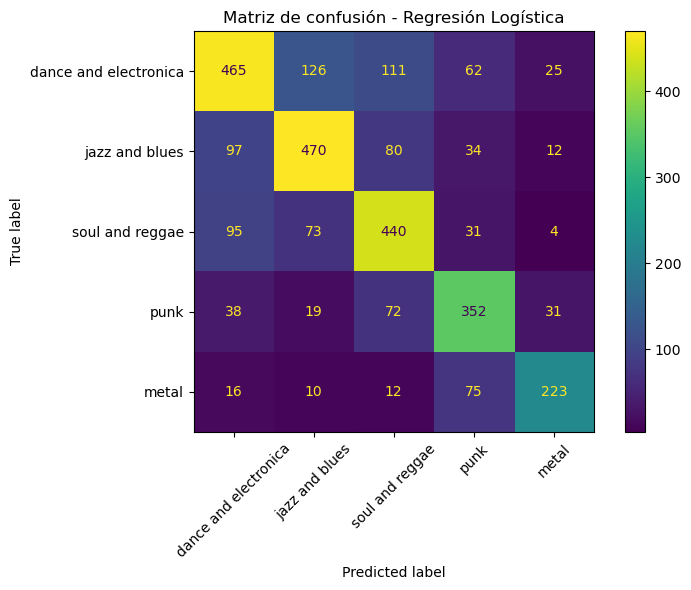

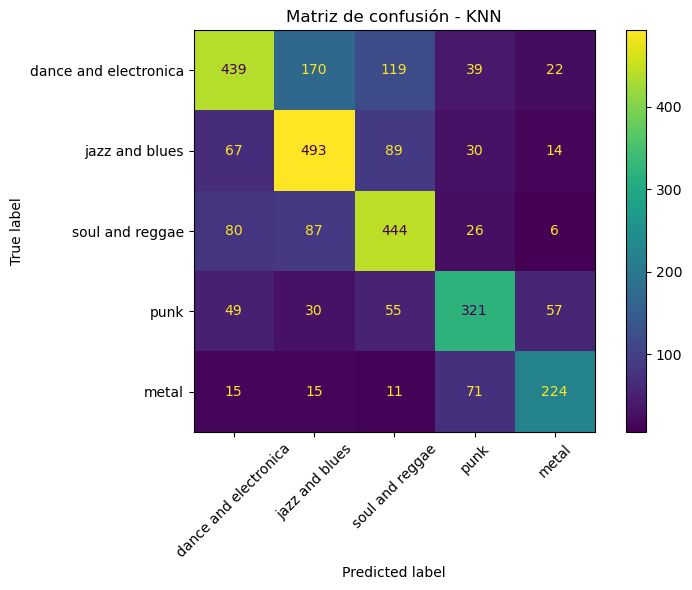

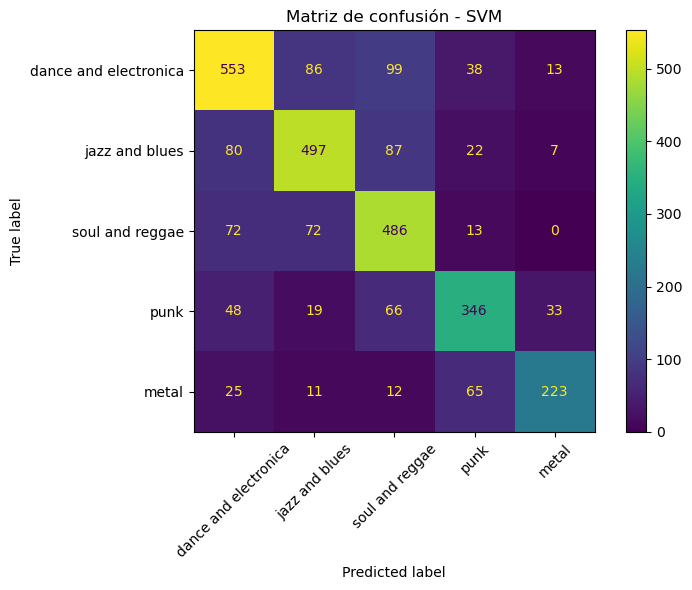

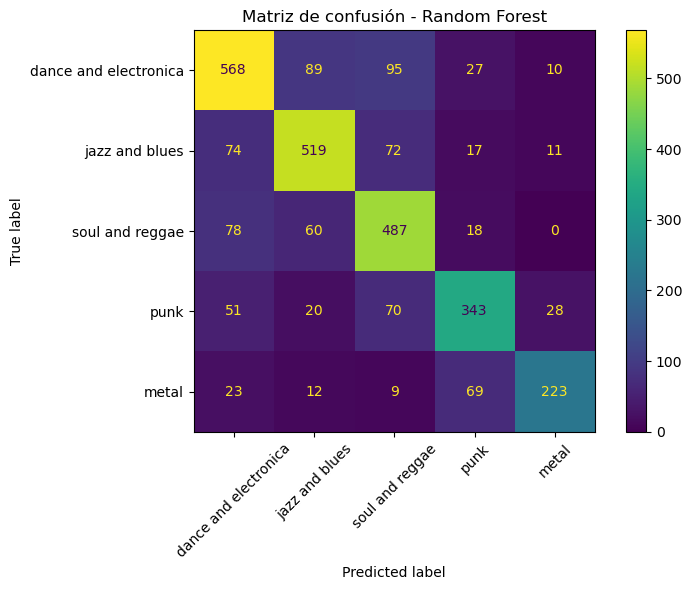

In [60]:
# Matrices de confusión

# Además de las métricas generales de evaluación, se utilizará la matriz de
# confusión para analizar con mayor detalle el comportamiento de cada modelo
# en las cinco clases de género musical.

# La matriz de confusión permite identificar las predicciones correctas y los
# errores de clasificación realizados por el modelo. Las filas representan
# las clases reales, mientras que las columnas representan las clases
# predichas por el modelo.

# La matriz de confusión permite observar cómo se distribuyen las
# predicciones correctas e incorrectas entre las cinco clases.

for nombre, y_pred in predicciones.items():

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=generos
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=generos
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp.plot(
        ax=ax,
        xticks_rotation=45
    )

    ax.set_title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

In [ ]:
# A partir de las métricas obtenidas sobre el conjunto de validación, Random
# Forest presentó el mejor desempeño general entre los cuatro modelos
# evaluados, alcanzando un Accuracy de 0.7198 y un F1 Macro de 0.7200.
# SVM presentó resultados similares, con un Accuracy de 0.7080 y un F1 Macro
# de 0.7097. Por otro lado, Regresión Logística y KNN presentaron un desempeño
# inferior, con F1 Macro de 0.6622 y 0.6495, respectivamente.

# El hecho de que Random Forest obtenga el mejor resultado en las diferentes
# métricas indica que, bajo las condiciones iniciales de evaluación, este modelo
# logra una mejor separación de las cinco clases de género musical. La
# diferencia con SVM es relativamente pequeña, por lo que ambos modelos se
# consideran alternativas relevantes para las siguientes etapas.

# Las matrices de confusión permiten observar que los modelos presentan
# dificultades para distinguir algunas clases entre sí. En particular, se
# observan confusiones entre géneros como dance and electronica y soul and
# reggae, así como entre punk y metal. Estas confusiones muestran que algunas
# características acústicas utilizadas por los modelos pueden presentar
# patrones similares entre determinados géneros.

# En el caso de Random Forest, aunque metal es la clase con menor cantidad de
# observaciones, el modelo logra identificar correctamente una parte de esta
# clase. No obstante, se observa una cantidad relevante de canciones de metal
# clasificadas como punk, lo que sugiere una dificultad para diferenciar estos
# dos géneros.

# Estos resultados corresponden al baseline, ya que los modelos fueron
# evaluados inicialmente sin aplicar técnicas de balanceo ni una búsqueda
# exhaustiva de hiperparámetros. A partir de este punto, se pueden comparar
# técnicas de manejo del desbalance y realizar una optimización de
# hiperparámetros para determinar si es posible mejorar el desempeño del
# modelo antes de realizar la evaluación final sobre el conjunto de prueba.

In [63]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
# ============================================================
# 1. OVERSAMPLING
# ============================================================

over_sampler = RandomOverSampler(
    sampling_strategy="not majority",
    random_state=42
)

X_train_over, y_train_over = over_sampler.fit_resample(
    X_train,
    y_train
)


# ============================================================
# 2. UNDERSAMPLING
# ============================================================

under_sampler = RandomUnderSampler(
    sampling_strategy="not minority",
    random_state=42
)

X_train_under, y_train_under = under_sampler.fit_resample(
    X_train,
    y_train
)


# ============================================================
# 3. SMOTE
# ============================================================

smote = SMOTE(
    sampling_strategy="not majority",
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)


# ============================================================
# 4. UNDERSAMPLING + OVERSAMPLING
# ============================================================

# En esta estrategia primero reducimos las clases mayoritarias
# y posteriormente aumentamos las clases minoritarias.
#
# Se utiliza un objetivo de 2.000 observaciones por clase.
# Este valor debe ser menor o igual que las clases que serán
# reducidas mediante undersampling.

target_balance = 2000

# Primero reducimos las clases que tienen más de 2.000 observaciones.
# Las clases que tienen menos de 2.000 se mantienen sin modificar.

sampling_under = {
    clase: target_balance
    for clase, cantidad in y_train.value_counts().items()
    if cantidad > target_balance
}

under_over_1 = RandomUnderSampler(
    sampling_strategy=sampling_under,
    random_state=42
)

X_train_under_over, y_train_under_over = under_over_1.fit_resample(
    X_train,
    y_train
)

# Ahora aumentamos las clases que tienen menos de 2.000 observaciones.
# De esta manera todas las clases terminan con la misma cantidad.

sampling_over = {
    clase: target_balance
    for clase, cantidad in y_train_under_over.value_counts().items()
    if cantidad < target_balance
}

under_over_2 = RandomOverSampler(
    sampling_strategy=sampling_over,
    random_state=42
)

X_train_under_over, y_train_under_over = under_over_2.fit_resample(
    X_train_under_over,
    y_train_under_over
)

# Comparación de la distribución de clases después de cada estrategia

print("Distribución original:")
print(y_train.value_counts())

print("\nOversampling:")
print(y_train_over.value_counts())

print("\nUndersampling:")
print(y_train_under.value_counts())

print("\nSMOTE:")
print(y_train_smote.value_counts())

print("\nUndersampling + Oversampling:")
print(y_train_under_over.value_counts())

Distribución original:
genre
dance and electronica    3158
jazz and blues           2770
soul and reggae          2570
punk                     2048
metal                    1346
Name: count, dtype: int64

Oversampling:
genre
punk                     3158
metal                    3158
dance and electronica    3158
jazz and blues           3158
soul and reggae          3158
Name: count, dtype: int64

Undersampling:
genre
dance and electronica    1346
jazz and blues           1346
metal                    1346
punk                     1346
soul and reggae          1346
Name: count, dtype: int64

SMOTE:
genre
punk                     3158
metal                    3158
dance and electronica    3158
jazz and blues           3158
soul and reggae          3158
Name: count, dtype: int64

Undersampling + Oversampling:
genre
dance and electronica    2000
jazz and blues           2000
metal                    2000
punk                     2000
soul and reggae          2000
Name: count, dtype: int

In [64]:
# Preparar los datos balanceados para los modelos sensibles a la escala.

# Cada scaler se ajusta únicamente sobre el conjunto de entrenamiento
# correspondiente. De esta manera se evita utilizar información de
# validación o prueba durante el preprocesamiento.

from sklearn.preprocessing import StandardScaler

scalers = {}

# Oversampling
scaler_over = StandardScaler()
X_train_over_scaled = scaler_over.fit_transform(X_train_over)
X_val_over_scaled = scaler_over.transform(X_val)

# Undersampling
scaler_under = StandardScaler()
X_train_under_scaled = scaler_under.fit_transform(X_train_under)
X_val_under_scaled = scaler_under.transform(X_val)

# SMOTE
scaler_smote = StandardScaler()
X_train_smote_scaled = scaler_smote.fit_transform(X_train_smote)
X_val_smote_scaled = scaler_smote.transform(X_val)

# Undersampling + Oversampling
scaler_under_over = StandardScaler()
X_train_under_over_scaled = scaler_under_over.fit_transform(
    X_train_under_over
)
X_val_under_over_scaled = scaler_under_over.transform(X_val)

In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

resultados_balanceo = []

estrategias = {
    "Oversampling": (
        X_train_over,
        y_train_over,
        X_train_over_scaled,
        X_val_over_scaled
    ),
    "Undersampling": (
        X_train_under,
        y_train_under,
        X_train_under_scaled,
        X_val_under_scaled
    ),
    "SMOTE": (
        X_train_smote,
        y_train_smote,
        X_train_smote_scaled,
        X_val_smote_scaled
    ),
    "Under + Over": (
        X_train_under_over,
        y_train_under_over,
        X_train_under_over_scaled,
        X_val_under_over_scaled
    )
}

for nombre_estrategia, (
    X_train_original,
    y_train_balanceado,
    X_train_scaled_balanceado,
    X_val_scaled
) in estrategias.items():

    # SVM
    modelo = SVC()

    modelo.fit(
        X_train_scaled_balanceado,
        y_train_balanceado
    )

    y_pred = modelo.predict(X_val_scaled)

    resultados_balanceo.append({
        "Modelo": "SVM",
        "Estrategia": nombre_estrategia,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision Macro": precision_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        )
    })

    # Random Forest
    modelo = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(
        X_train_original,
        y_train_balanceado
    )

    # Random Forest no necesita datos estandarizados
    y_pred = modelo.predict(X_val)

    resultados_balanceo.append({
        "Modelo": "Random Forest",
        "Estrategia": nombre_estrategia,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision Macro": precision_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        )
    })


# Crear tabla comparativa
resultados_balanceo_df = pd.DataFrame(resultados_balanceo)

resultados_balanceo_df = resultados_balanceo_df.sort_values(
    by="F1 Macro",
    ascending=False
).reset_index(drop=True)

display(resultados_balanceo_df)

,Modelo,Estrategia,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Random Forest,SMOTE,0.718130,0.724356,0.718491,0.720191
1,Random Forest,Oversampling,0.714094,0.722530,0.712733,0.716197
2,SVM,SMOTE,0.712412,0.718831,0.713274,0.714886
3,SVM,Oversampling,0.710057,0.716254,0.713808,0.713372
4,SVM,Under + Over,0.703330,0.709578,0.707132,0.706314
5,Random Forest,Under + Over,0.700303,0.708335,0.702371,0.702699
6,Random Forest,Undersampling,0.699294,0.703285,0.704858,0.700937
7,SVM,Undersampling,0.694921,0.700051,0.699706,0.697867


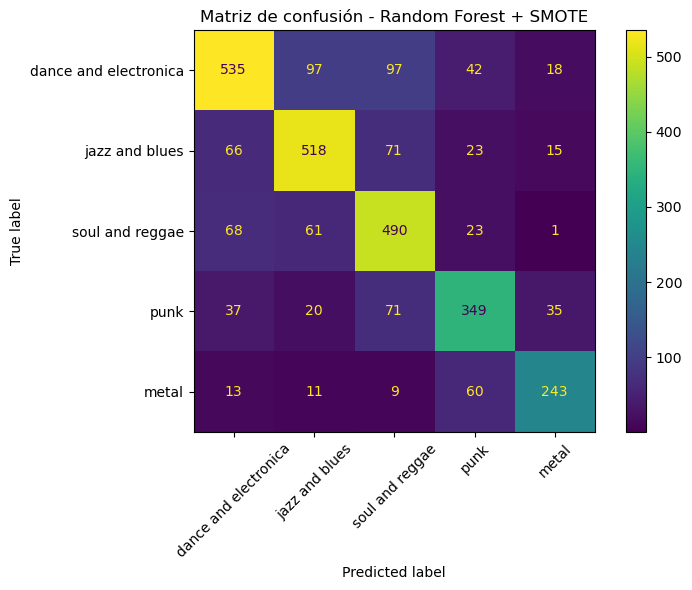

In [49]:
# Matriz de confusión del mejor modelo hasta el momento:
# Random Forest + SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Entrenar Random Forest utilizando el conjunto de entrenamiento
# balanceado mediante SMOTE.
modelo_rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

modelo_rf_smote.fit(
    X_train_smote,
    y_train_smote
)

# Realizar las predicciones sobre el conjunto de validación original.
y_pred_rf_smote = modelo_rf_smote.predict(X_val)

# Calcular la matriz de confusión.
cm_rf_smote = confusion_matrix(
    y_val,
    y_pred_rf_smote,
    labels=generos
)

# Visualizar la matriz de confusión.
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_smote,
    display_labels=generos
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

ax.set_title("Matriz de confusión - Random Forest + SMOTE")
plt.tight_layout()
plt.show()

In [19]:
# Análisis de la matriz de confusión - Random Forest + SMOTE

# La matriz de confusión muestra que Random Forest con SMOTE logra identificar
# correctamente 535 canciones de dance and electronica, 518 de jazz and blues,
# 490 de soul and reggae, 349 de punk y 243 de metal.

# Las principales confusiones se presentan entre dance and electronica y soul
# and reggae, entre dance and electronica y jazz and blues, y entre punk y
# soul and reggae. También se observa una confusión importante entre metal y
# punk, con 60 canciones de metal clasificadas como punk.

# Estas confusiones indican que algunas de las características acústicas
# utilizadas presentan patrones similares entre determinados géneros, lo que
# dificulta su diferenciación.

# Random Forest con SMOTE obtuvo un F1 Macro de 0.7202 sobre el conjunto de
# validación. Aunque este fue el mejor resultado entre las estrategias de
# balanceo evaluadas, la diferencia frente a Random Forest sin balanceo,
# cuyo F1 Macro fue de 0.7200, es mínima (0.0002).

# Debido a que la aplicación de SMOTE no produjo una mejora relevante en el
# desempeño global, se mantiene Random Forest sin balanceo como modelo de
# referencia para la siguiente etapa de optimización de hiperparámetros.

In [66]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Crear el modelo Random Forest que será optimizado.
# No se aplica SMOTE, ya que la comparación anterior mostró que
# su mejora frente al modelo sin balanceo fue mínima.

modelo_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Definir los hiperparámetros que serán explorados.

param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Búsqueda aleatoria utilizando validación cruzada.
#
# F1 Macro se utiliza como métrica principal debido al desbalance
# existente entre las cinco clases.

random_search = RandomizedSearchCV(
    estimator=modelo_rf,
    param_distributions=param_dist,
    n_iter=15,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# La búsqueda se realiza únicamente sobre el conjunto de entrenamiento.
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,estimator,RandomForestC...ndom_state=42)
,param_distributions,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,n_iter,15
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [67]:
print("Mejores hiperparámetros:")
print(random_search.best_params_)

print("\nMejor F1 Macro obtenido durante la validación cruzada:")
print(random_search.best_score_)

Mejores hiperparámetros:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

Mejor F1 Macro obtenido durante la validación cruzada:
0.7082588694139361


In [68]:
# Obtener el mejor modelo encontrado durante la búsqueda.
mejor_modelo_rf = random_search.best_estimator_

# Predicciones sobre el conjunto de validación.
y_pred_rf_opt = mejor_modelo_rf.predict(X_val)

# Calcular métricas sobre validación.
accuracy_opt = accuracy_score(y_val, y_pred_rf_opt)

precision_opt = precision_score(
    y_val,
    y_pred_rf_opt,
    average="macro",
    zero_division=0
)

recall_opt = recall_score(
    y_val,
    y_pred_rf_opt,
    average="macro",
    zero_division=0
)

f1_opt = f1_score(
    y_val,
    y_pred_rf_opt,
    average="macro",
    zero_division=0
)

print("Resultados del Random Forest optimizado")
print(f"Accuracy:        {accuracy_opt:.4f}")
print(f"Precision Macro: {precision_opt:.4f}")
print(f"Recall Macro:    {recall_opt:.4f}")
print(f"F1 Macro:        {f1_opt:.4f}")

Resultados del Random Forest optimizado
Accuracy:        0.7164
Precision Macro: 0.7285
Recall Macro:    0.7087
F1 Macro:        0.7161


In [24]:
# Análisis del Random Forest optimizado

# La búsqueda de hiperparámetros mediante RandomizedSearchCV encontró como
# configuración óptima 300 árboles, una profundidad máxima de 30, un mínimo
# de 2 muestras para dividir un nodo, un mínimo de 1 muestra por hoja y
# log2 como criterio para la cantidad de características consideradas.

# Sin embargo, al evaluar esta configuración sobre el conjunto de validación,
# se obtuvo un Accuracy de 0.7164, una Precision Macro de 0.7285, un Recall
# Macro de 0.7087 y un F1 Macro de 0.7161.

# El F1 Macro del modelo optimizado fue inferior al obtenido por el Random
# Forest baseline, que alcanzó un F1 Macro de 0.7200. Por lo tanto, la
# optimización de hiperparámetros realizada no produjo una mejora en el
# desempeño del modelo sobre el conjunto de validación.

# En consecuencia, se mantiene el Random Forest baseline como modelo de
# referencia para la evaluación final sobre el conjunto de prueba.

In [70]:
# Evaluación final sobre el conjunto de prueba

# El conjunto de prueba se ha mantenido separado durante todo el proceso de
# selección de modelos, balanceo y optimización de hiperparámetros.
# Por esta razón, esta evaluación permite estimar el desempeño final del
# modelo sobre datos que no fueron utilizados durante su desarrollo.

# Crear y entrenar nuevamente el Random Forest baseline seleccionado.
modelo_final = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

modelo_final.fit(X_train, y_train)

# Realizar las predicciones sobre el conjunto de prueba.
y_pred_test = modelo_final.predict(X_test)

# Calcular las métricas finales.
accuracy_test = accuracy_score(
    y_test,
    y_pred_test
)

precision_test = precision_score(
    y_test,
    y_pred_test,
    average="macro",
    zero_division=0
)

recall_test = recall_score(
    y_test,
    y_pred_test,
    average="macro",
    zero_division=0
)

f1_test = f1_score(
    y_test,
    y_pred_test,
    average="macro",
    zero_division=0
)

print("Resultados finales sobre el conjunto de prueba")
print(f"Accuracy:        {accuracy_test:.4f}")
print(f"Precision Macro: {precision_test:.4f}")
print(f"Recall Macro:    {recall_test:.4f}")
print(f"F1 Macro:        {f1_test:.4f}")

Resultados finales sobre el conjunto de prueba
Accuracy:        0.7318
Precision Macro: 0.7470
Recall Macro:    0.7282
F1 Macro:        0.7356


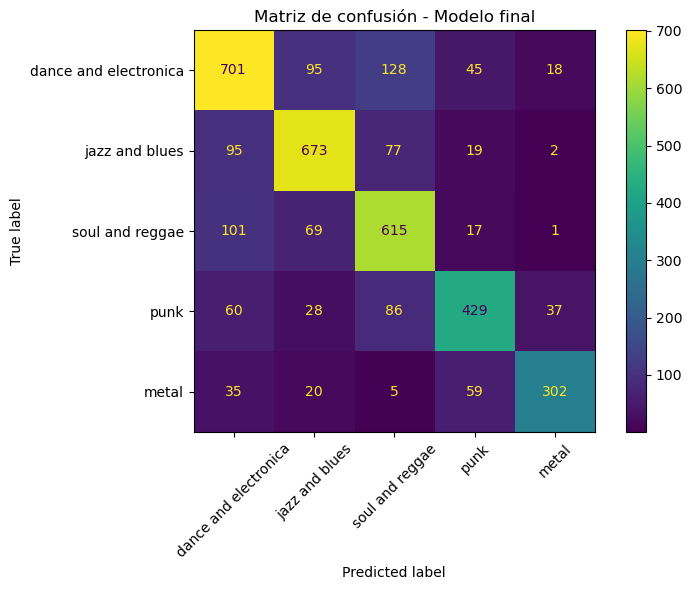

In [71]:
# Matriz de confusión final

cm_test = confusion_matrix(
    y_test,
    y_pred_test,
    labels=generos
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=generos
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

ax.set_title("Matriz de confusión - Modelo final")
plt.tight_layout()
plt.show()

In [72]:
from sklearn.metrics import classification_report

print("Reporte de clasificación final:")
print(
    classification_report(
        y_test,
        y_pred_test,
        labels=generos,
        zero_division=0
    )
)

Reporte de clasificación final:
                       precision    recall  f1-score   support

dance and electronica       0.71      0.71      0.71       987
       jazz and blues       0.76      0.78      0.77       866
      soul and reggae       0.68      0.77      0.72       803
                 punk       0.75      0.67      0.71       640
                metal       0.84      0.72      0.77       421

             accuracy                           0.73      3717
            macro avg       0.75      0.73      0.74      3717
         weighted avg       0.74      0.73      0.73      3717



In [ ]:
# Análisis de los resultados finales

# La evaluación final sobre el conjunto de prueba muestra que el Random Forest
# seleccionado obtuvo un Accuracy de 0.7318, una Precision Macro de 0.7470,
# un Recall Macro de 0.7282 y un F1 Macro de 0.7356.

# El F1 Macro de 0.7356 indica que el modelo presenta un desempeño general
# adecuado para la clasificación de los cinco géneros musicales, considerando
# por igual el desempeño sobre cada una de las clases.

# La Precision Macro de 0.7470 indica que, en promedio, las predicciones
# realizadas para las cinco clases presentan una proporción relativamente alta
# de predicciones correctas. Por otro lado, el Recall Macro de 0.7282 indica
# que el modelo logra identificar una proporción importante de las canciones
# pertenecientes a cada género.

# El F1 Macro obtenido sobre el conjunto de prueba fue superior al obtenido
# sobre el conjunto de validación (0.7200). Esta diferencia puede presentarse
# debido a las características y composición particulares de cada conjunto,
# y no implica necesariamente un problema en el modelo.

# Debido a que el conjunto de prueba permaneció separado durante las etapas de
# selección, balanceo y optimización, estos resultados constituyen la estimación
# final del desempeño del modelo sobre datos no utilizados durante su desarrollo.

In [ ]:
# Análisis de la matriz de confusión y reporte de clasificación final

# La matriz de confusión final muestra que el modelo logra identificar
# correctamente 701 canciones de dance and electronica, 673 de jazz and blues,
# 615 de soul and reggae, 429 de punk y 302 de metal.

# Las principales confusiones se presentan entre géneros con características
# acústicas similares. En particular, se clasificaron 128 canciones de dance
# and electronica como soul and reggae, mientras que 101 canciones de soul and
# reggae fueron clasificadas como dance and electronica. También se observan
# 95 canciones de dance and electronica clasificadas como jazz and blues y
# 95 canciones de jazz and blues clasificadas como dance and electronica.

# Otra confusión importante se presenta entre punk y soul and reggae, con
# 86 canciones de punk clasificadas como soul and reggae. Asimismo, 59
# canciones de metal fueron clasificadas como punk.

# De acuerdo con el reporte de clasificación, jazz and blues y metal obtuvieron
# los mayores F1-score individuales, con valores de 0.77. Soul and reggae
# obtuvo un F1-score de 0.72, mientras que dance and electronica y punk
# obtuvieron un F1-score de 0.71.

# En términos globales, el modelo obtuvo un Accuracy de 0.7318 y un F1 Macro
# de 0.7356 sobre el conjunto de prueba. La Precision Macro fue de 0.7470 y
# el Recall Macro de 0.7282.

# Estos resultados representan el desempeño final del modelo sobre datos que
# permanecieron separados durante las etapas de entrenamiento y selección.
# Por lo tanto, el F1 Macro de 0.7356 constituye la métrica principal utilizada
# para reportar el desempeño final del clasificador.